# 03 · Hotspots: where exactly do serious collisions cluster?

Notebook 02 showed *which roads* have the most harm. Here we find the **exact locations**: junctions and short stretches of road where collisions keep happening.

We use two methods that answer slightly different questions:

| Method | Question it answers | Output |
|---|---|---|
| **DBSCAN clustering** | *Where are tight groups of collisions?* | A ranked list of specific sites (e.g. a junction) |
| **Getis-Ord Gi\*** | *Which areas have significantly more harm than chance would explain?* | A map of statistically significant hot (and cold) spots |

Using both is stronger than either alone. DBSCAN finds concrete sites to act on, and Gi\* proves the pattern isn't random.

**Severity score** used for ranking: Slight = 1, Serious = 3, Fatal = 5. This is a common convention in local road safety work. It gives serious harm more weight without letting a single, partly random, fatal crash dominate. We check later that the rankings hold up with other weightings.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from folium import plugins
from shapely.geometry import box
from sklearn.cluster import DBSCAN
from libpysal.weights import DistanceBand
from esda.getisord import G_Local
from esda import fdr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN, GEO, FIG, REPORT = ROOT / "data/clean", ROOT / "data/geo", ROOT / "report/figures", ROOT / "report"

c = pd.read_parquet(CLEAN / "collisions.parquet").dropna(subset=["location_easting_osgr"])
WEIGHTS = {1: 5, 2: 3, 3: 1}                      # collision_severity code -> score
c["score"] = c["collision_severity"].map(WEIGHTS)

# British National Grid (EPSG:27700) is in metres, which suits distance-based methods.
gc = gpd.GeoDataFrame(c, geometry=gpd.points_from_xy(c.location_easting_osgr, c.location_northing_osgr), crs=27700)
districts = gpd.read_file(GEO / "herts_districts.geojson").to_crs(27700)[["LAD24CD", "LAD24NM", "geometry"]]
county = districts.dissolve()

print(f"{len(gc):,} mapped collisions · county area {county.area.iloc[0]/1e6:,.0f} km²")

8,374 mapped collisions · county area 1,643 km²


## Part A · DBSCAN: finding collision clusters

DBSCAN groups points that are close together:
- **eps:** how close two collisions must be to count as neighbours (metres)
- **min_samples:** how many collisions are needed to form a cluster

Collisions that aren't in any dense group are labelled *noise* and left out. That's the point: we only want repeat locations.

### Choosing the parameters
A quick sensitivity check shows how the results change with different settings.

In [2]:
XY = np.c_[gc.location_easting_osgr, gc.location_northing_osgr]
rows = []
for eps in [50, 75, 100, 150]:
    for ms in [5, 8, 12]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(XY)
        n = lab.max() + 1
        in_cl = lab >= 0
        rows.append({"eps_m": eps, "min_samples": ms, "clusters": n,
                     "% collisions in clusters": round(in_cl.mean() * 100, 1),
                     "% KSI in clusters": round(gc.loc[in_cl, "is_ksi"].sum() / gc.is_ksi.sum() * 100, 1)})
pd.DataFrame(rows).pivot(index="eps_m", columns="min_samples", values=["clusters", "% collisions in clusters"])

clusters              % collisions in clusters            
min_samples       5      8     12                       5     8     12
eps_m                                                                 
50             231.0   60.0  18.0                     22.4   9.4   4.2
75             287.0  102.0  32.0                     31.8  16.6   7.5
100            330.0  135.0  53.0                     40.0  23.8  12.7
150            355.0  178.0  77.0                     54.6  36.9  21.8

**Chosen: eps = 100 m, min_samples = 8** (8+ collisions within 100 m over 5 years). 100 m roughly covers a junction and its approaches, which is the scale engineers work at. 8 collisions means a site averages more than one injury crash every year. Smaller values split junctions apart, and larger ones merge separate sites along a road.

In [3]:
EPS, MIN_SAMPLES = 100, 8
gc["cluster"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(XY)

def road_label(cls, num):
    prefix = {1: "M", 2: "A", 3: "A", 4: "B", 5: "C"}
    if cls in prefix and pd.notna(num) and num > 0:
        return f"{prefix[cls]}{int(num)}" + ("(M)" if cls == 2 else "")
    return "Unclassified" if cls == 6 else None
gc["second_road"] = [road_label(a, b) for a, b in zip(gc.second_road_class, gc.second_road_number)]

def describe(g):
    road = g.road_name.mode().iat[0]
    second = g.second_road.dropna()
    second = second[second != road]
    place = f"{road} / {second.mode().iat[0]}" if len(second) >= 0.3 * len(g) else road
    return pd.Series({
        "location": place,
        "district": g.district.mode().iat[0],
        "collisions": len(g),
        "fatal": (g.collision_severity == 1).sum(),
        "serious": (g.collision_severity == 2).sum(),
        "ksi": g.is_ksi.sum(),
        "score": g.score.sum(),
        "ksi_rate": g.is_ksi.mean(),
        "pct_vulnerable": g.vulnerable_user_hurt.mean(),
        "pct_dark": g.is_dark.mean(),
        "pct_junction": g.is_junction.mean(),
        "peak_time": g.time_band.mode().iat[0],
        "speed_limit": g.speed_limit.mode().iat[0] if g.speed_limit.notna().any() else np.nan,
        "years_with_collision": g.year.nunique(),
        "early_2021_23": g.year.le(2023).sum(),
        "late_2024_25": g.year.ge(2024).sum(),
        "radius_m": float(np.hypot(g.location_easting_osgr - g.location_easting_osgr.mean(),
                                   g.location_northing_osgr - g.location_northing_osgr.mean()).max()),
        "easting": g.location_easting_osgr.mean(), "northing": g.location_northing_osgr.mean(),
        "latitude": g.latitude.mean(), "longitude": g.longitude.mean(),
    })

clusters = gc[gc.cluster >= 0].groupby("cluster").apply(describe, include_groups=False)
clusters = clusters.sort_values(["score", "ksi"], ascending=False)
clusters.insert(0, "rank", range(1, len(clusters) + 1))
print(f"{len(clusters)} clusters containing {clusters.collisions.sum():,} collisions "
      f"({clusters.collisions.sum()/len(gc):.0%} of all, {clusters.ksi.sum()/gc.is_ksi.sum():.0%} of KSI)")

135 clusters containing 1,989 collisions (24% of all, 18% of KSI)


### Adding place names
Road numbers alone are ambiguous; the A414 runs right across the county. We look up the nearest place for the top 40 sites with OpenStreetMap's free reverse-geocoding service (Nominatim). Only the cluster's centre point is sent. Results are cached in `data/geo/place_cache.json`, so the service is only called once per site (its usage policy allows 1 request a second).

In [4]:
import json, time, requests
CACHE = GEO / "place_cache.json"
cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}

def place_name(lat, lon):
    key = f"{lat:.4f},{lon:.4f}"
    if key not in cache:
        try:
            r = requests.get("https://nominatim.openstreetmap.org/reverse",
                             params={"format": "jsonv2", "lat": lat, "lon": lon, "zoom": 17, "addressdetails": 1},
                             headers={"User-Agent": "herts-collision-student-project/1.0"}, timeout=20)
            a = r.json().get("address", {})
            cache[key] = {"road": a.get("road"),
                          "area": a.get("suburb") or a.get("village") or a.get("town") or a.get("hamlet") or a.get("city")}
        except Exception as e:
            cache[key] = {"road": None, "area": None}
        time.sleep(1.1)
    return cache[key]

N_NAMED = 40
for cid, r in clusters.head(N_NAMED).iterrows():
    p = place_name(r.latitude, r.longitude)
    clusters.loc[cid, "near_road"], clusters.loc[cid, "area"] = p["road"], p["area"]
CACHE.write_text(json.dumps(cache, indent=1))

import re
def site_name(r):
    """e.g. 'Park Street Roundabout (A414), St Julians'. Falls back to road numbers when no local name."""
    road, area = r.get("near_road"), r.get("area")
    if pd.isna(area):
        return r.location
    if isinstance(road, str) and not re.fullmatch(r"[ABM]\d+(\(M\))?", road):
        return f"{road} ({r.location.replace(' / Unclassified', '')}), {area}"
    return f"{r.location.replace(' / Unclassified', '')}, {area}"
clusters["site"] = clusters.apply(site_name, axis=1)
clusters.head(N_NAMED)[["location", "near_road", "area", "site"]].head(10)

,location,near_road,area,site
cluster,,,,
59,A10,None,Churchgate,"A10, Churchgate"
63,A1081 / Unclassified,St Peter's Street,Townsend,"St Peter's Street (A1081), Townsend"
27,A414,Park Street Roundabout,St Julians,"Park Street Roundabout (A414), St Julians"
19,A411 / Unclassified,Exchange Road,Watford Heath,"Exchange Road (A411), Watford Heath"
12,M25 / A111,M25,Potters Bar,"M25 / A111, Potters Bar"
67,A41 / Unclassified,North Western Avenue,Bushey,"North Western Avenue (A41), Bushey"
17,M25 / A405,M25,St Stephen,"M25 / A405, St Stephen"
21,A4008,Otterspool Way,Bushey,"Otterspool Way (A4008), Bushey"
51,A414 / A6129,Jack Olding's Roundabout,Birchwood,"Jack Olding's Roundabout (A414 / A6129), Birch..."


### Top 20 collision clusters
Ranked by severity score. `years_with_collision = 5` means the site had collisions every single year, a strong sign that it's a persistent problem rather than bad luck.

In [5]:
top20 = clusters.head(20)
(top20[["rank", "site", "district", "collisions", "fatal", "serious", "ksi", "score", "ksi_rate",
        "pct_vulnerable", "pct_dark", "peak_time", "speed_limit", "years_with_collision"]]
 .style.format({"ksi_rate": "{:.0%}", "pct_vulnerable": "{:.0%}", "pct_dark": "{:.0%}", "speed_limit": "{:.0f}"})
 .background_gradient(subset=["score"], cmap="Reds").hide(axis="index"))

rank,site,district,collisions,fatal,serious,ksi,score,ksi_rate,pct_vulnerable,pct_dark,peak_time,speed_limit,years_with_collision
1,"A10, Churchgate",Broxbourne,78,0,10,10,98,13%,17%,24%,Daytime (10–15),40,5
2,"St Peter's Street (A1081), Townsend",St Albans,39,0,9,9,57,23%,67%,28%,Daytime (10–15),30,5
3,"Park Street Roundabout (A414), St Julians",St Albans,48,0,4,4,56,8%,25%,17%,Daytime (10–15),70,5
4,"Exchange Road (A411), Watford Heath",Watford,35,0,7,7,49,20%,74%,29%,Daytime (10–15),30,5
5,"M25 / A111, Potters Bar",Hertsmere,43,0,3,3,49,7%,2%,30%,Daytime (10–15),70,5
6,"North Western Avenue (A41), Bushey",Hertsmere,40,0,4,4,48,10%,40%,22%,Daytime (10–15),30,5
7,"M25 / A405, St Stephen",St Albans,42,0,3,3,48,7%,10%,36%,Daytime (10–15),70,5
8,"Otterspool Way (A4008), Bushey",Hertsmere,37,0,4,4,45,11%,11%,22%,Daytime (10–15),70,5
9,"Jack Olding's Roundabout (A414 / A6129), Birchwood",Welwyn Hatfield,26,0,6,6,38,23%,15%,19%,Evening peak (16–18),60,5
10,"M1, Abbots Langley",Three Rivers,28,0,4,4,36,14%,4%,39%,Daytime (10–15),70,5


### Is the ranking robust?
If the top sites change completely under a different severity weighting, the ranking isn't trustworthy. We compare our 1/3/5 weights with (a) plain collision count and (b) KSI-only.

In [6]:
alt = pd.DataFrame({
    "score_1_3_5": clusters.score.rank(ascending=False),
    "count_only": clusters.collisions.rank(ascending=False),
    "ksi_only": clusters.ksi.rank(ascending=False),
})
top_ids = set(clusters.head(20).index)
overlap = {k: len(top_ids & set(alt[k].nsmallest(20).index)) for k in ["count_only", "ksi_only"]}
print("Spearman rank correlation with our score:")
print(alt.corr(method="spearman")["score_1_3_5"].round(2).to_string())
print("\nOverlap with our top 20:", {k: f"{v}/20" for k, v in overlap.items()})

Spearman rank correlation with our score:
score_1_3_5    1.00
count_only     0.88
ksi_only       0.78

Overlap with our top 20: {'count_only': '16/20', 'ksi_only': '13/20'}


### Persistence: are the hotspots stable over time?
A real hotspot should show up in both halves of the period, not only in one bad year.

In [7]:
p = clusters.assign(both=lambda d: (d.early_2021_23 > 0) & (d.late_2024_25 > 0))
print(f"Clusters with collisions in both 2021–23 and 2024–25: {p.both.mean():.0%}")
print(f"Top-20 clusters active in all 5 years: {(top20.years_with_collision == 5).sum()}/20")
trend = top20[["site", "early_2021_23", "late_2024_25"]].assign(
    per_year_early=lambda d: (d.early_2021_23 / 3).round(1), per_year_late=lambda d: (d.late_2024_25 / 2).round(1))
trend["change"] = np.where(trend.per_year_late > trend.per_year_early * 1.25, "▲ worse",
                  np.where(trend.per_year_late < trend.per_year_early * 0.75, "▼ better", "● similar"))
trend.drop(columns=["early_2021_23", "late_2024_25"])

Clusters with collisions in both 2021–23 and 2024–25: 97%
Top-20 clusters active in all 5 years: 20/20


,site,per_year_early,per_year_late,change
cluster,,,,
59,"A10, Churchgate",17.3,13.0,● similar
63,"St Peter's Street (A1081), Townsend",9.7,5.0,▼ better
27,"Park Street Roundabout (A414), St Julians",10.3,8.5,● similar
19,"Exchange Road (A411), Watford Heath",6.7,7.5,● similar
12,"M25 / A111, Potters Bar",9.7,7.0,▼ better
67,"North Western Avenue (A41), Bushey",6.3,10.5,▲ worse
17,"M25 / A405, St Stephen",9.3,7.0,● similar
21,"Otterspool Way (A4008), Bushey",6.7,8.5,▲ worse
51,"Jack Olding's Roundabout (A414 / A6129), Birch...",5.7,4.5,● similar


## Part B · Getis-Ord Gi\*: statistically significant hotspots

DBSCAN finds dense groups, but it doesn't test whether they're unusual. Gi\* does:

1. Cover the county with a grid of **500 m × 500 m cells**, including cells with zero collisions (they matter for the comparison).
2. Add up the **severity score** in each cell.
3. For each cell, compare the total of *it and its neighbours* (within 750 m) with what we'd expect if harm were spread randomly.
4. A high **z-score** with a low **p-value** marks a **hot spot**: a whole area with more harm than chance would explain.

The p-values come from 999 random permutations. With thousands of cells, some would look "significant" by luck, so we also apply a **False Discovery Rate (FDR)** correction for the strictest version.

In [8]:
CELL = 500
xmin, ymin, xmax, ymax = county.total_bounds
grid = gpd.GeoDataFrame(geometry=[box(x, y, x + CELL, y + CELL)
                                  for x in np.arange(xmin, xmax, CELL) for y in np.arange(ymin, ymax, CELL)], crs=27700)
grid = grid[grid.intersects(county.geometry.iloc[0])].reset_index(drop=True)
grid["cell_id"] = grid.index

joined = gpd.sjoin(gc[["score", "is_ksi", "geometry"]], grid, predicate="within")
agg = joined.groupby("cell_id").agg(score=("score", "sum"), collisions=("score", "size"), ksi=("is_ksi", "sum"))
grid = grid.join(agg, on="cell_id").fillna({"score": 0, "collisions": 0, "ksi": 0})
print(f"{len(grid):,} cells · {(grid.collisions > 0).mean():.0%} have at least one collision")

6,927 cells · 29% have at least one collision


In [9]:
np.random.seed(42)
centroids = np.c_[grid.centroid.x, grid.centroid.y]
w = DistanceBand(centroids, threshold=CELL * 1.5, binary=True, silence_warnings=True)   # cell + 8 neighbours
gi = G_Local(grid["score"].values, w, transform="B", star=True, permutations=999, seed=42)

grid["gi_z"], grid["gi_p"] = gi.Zs, gi.p_sim
fdr_cut = fdr(gi.p_sim, 0.05)

def classify(z, p):
    if z > 0 and p <= fdr_cut: return "Hot spot (FDR)"
    if z > 0 and p <= 0.01:    return "Hot spot 99%"
    if z > 0 and p <= 0.05:    return "Hot spot 95%"
    if z < 0 and p <= 0.05:    return "Cold spot 95%"
    return "Not significant"
grid["hotspot"] = [classify(z, p) for z, p in zip(grid.gi_z, grid.gi_p)]
grid["district"] = gpd.sjoin(grid[["geometry"]].set_geometry(grid.centroid), districts, predicate="within")["LAD24NM"]

print(f"FDR p-value cut-off: {fdr_cut:.4f}")
grid.hotspot.value_counts().to_frame("cells")

FDR p-value cut-off: 0.0173


,cells
hotspot,
Not significant,4280
Cold spot 95%,1915
Hot spot (FDR),488
Hot spot 95%,244


In [10]:
hot = grid[grid.hotspot.str.startswith("Hot")]
by_district = (hot.groupby("district").agg(hot_cells=("cell_id", "size"), hot_cells_fdr=("hotspot", lambda s: (s == "Hot spot (FDR)").sum()),
                                           ksi_in_hot=("ksi", "sum"))
               .join(grid.groupby("district").agg(all_cells=("cell_id", "size"))))
by_district["% of district area hot"] = (by_district.hot_cells / by_district.all_cells * 100).round(1)
print(f"Hot-spot cells cover {len(hot)/len(grid):.1%} of the county but contain {hot.ksi.sum()/grid.ksi.sum():.0%} of KSI collisions.")
by_district.sort_values("hot_cells", ascending=False)

Hot-spot cells cover 10.6% of the county but contain 47% of KSI collisions.


,hot_cells,hot_cells_fdr,ksi_in_hot,all_cells,% of district area hot
district,,,,,
Hertsmere,136,81,138.0,407,33.4
St Albans,116,76,125.0,649,17.9
Welwyn Hatfield,75,50,74.0,516,14.5
Dacorum,67,54,88.0,846,7.9
Stevenage,65,47,75.0,106,61.3
Broxbourne,62,50,86.0,210,29.5
North Hertfordshire,61,33,63.0,1508,4.0
Watford,61,55,108.0,84,72.6
East Hertfordshire,41,26,38.0,1895,2.2


### Do the two methods agree?
If most DBSCAN top-20 sites fall inside Gi\* hot spots, the two independent methods confirm each other.

In [11]:
cl_pts = gpd.GeoDataFrame(clusters, geometry=gpd.points_from_xy(clusters.easting, clusters.northing), crs=27700)
cl_pts = gpd.sjoin(cl_pts, grid[["hotspot", "gi_z", "geometry"]], predicate="within", how="left")
clusters["gi_hotspot"] = cl_pts["hotspot"].values
clusters["confirmed"] = clusters.gi_hotspot.fillna("").str.startswith("Hot")
print(f"Top-20 DBSCAN sites inside a Gi* hot spot: {clusters.head(20).confirmed.sum()}/20")
print(f"All DBSCAN clusters inside a Gi* hot spot: {clusters.confirmed.mean():.0%}")

Top-20 DBSCAN sites inside a Gi* hot spot: 16/20
All DBSCAN clusters inside a Gi* hot spot: 69%


## Part C · Maps
### Static overview (for the report)

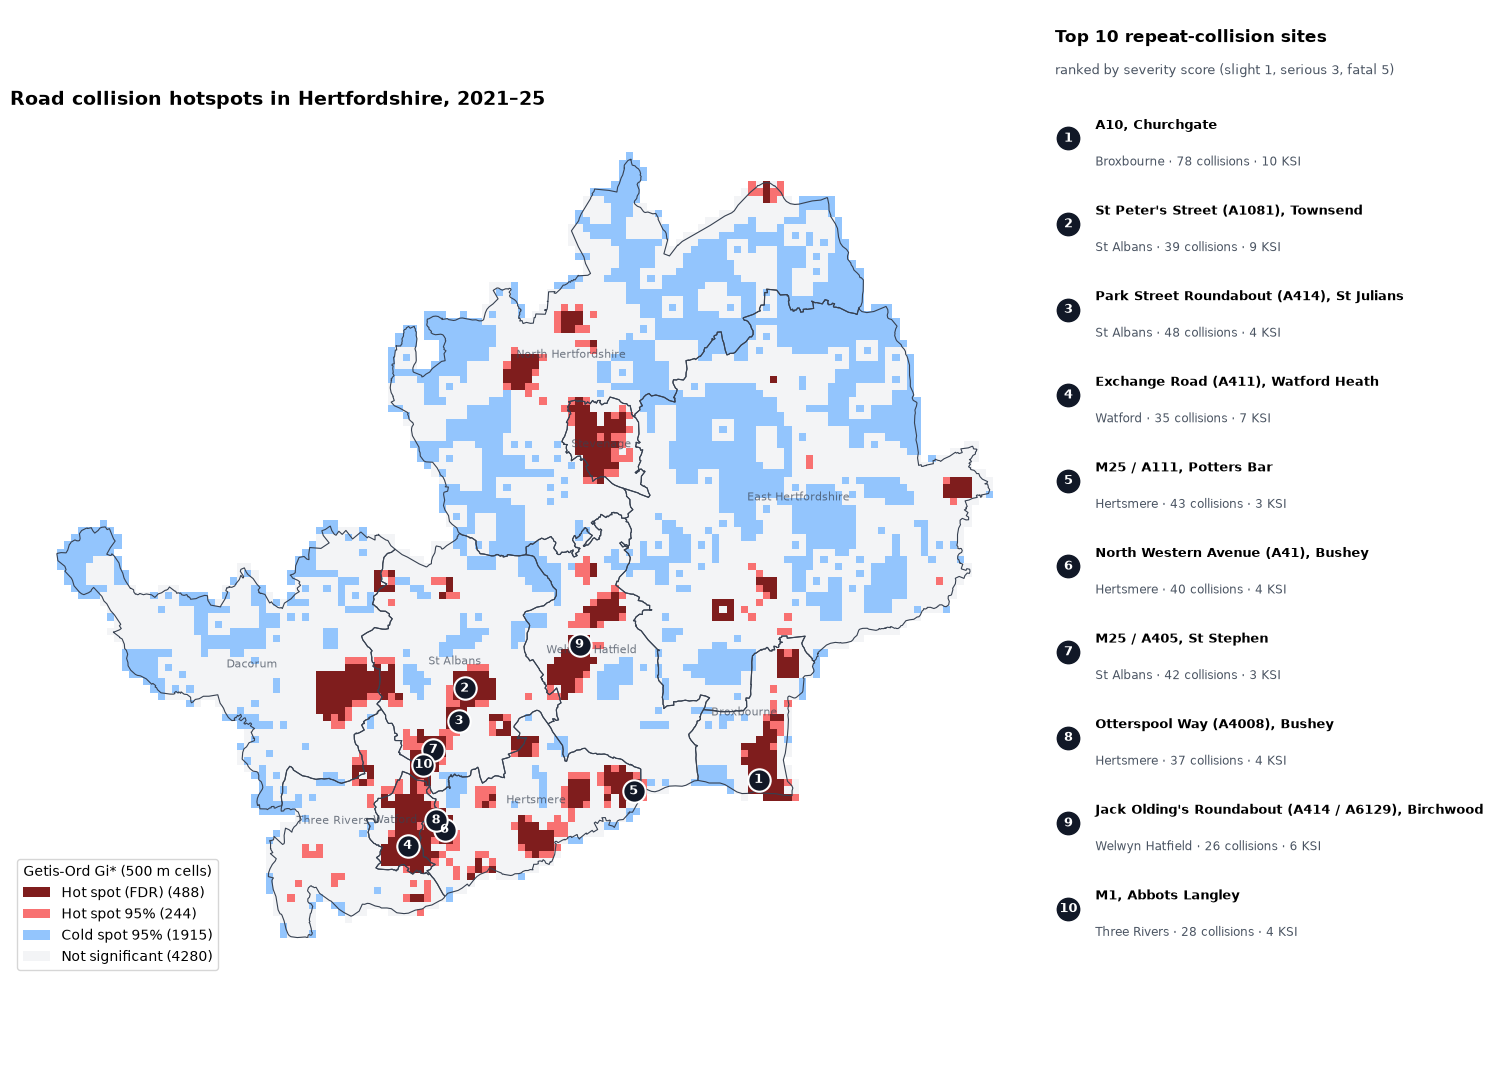

In [12]:
colors = {"Hot spot (FDR)": "#7f1d1d", "Hot spot 99%": "#dc2626", "Hot spot 95%": "#f87171",
          "Cold spot 95%": "#93c5fd", "Not significant": "#f3f4f6"}
fig, (ax, lx) = plt.subplots(1, 2, figsize=(16, 11), gridspec_kw={"width_ratios": [2.3, 1]})
for label, col in colors.items():
    sub = grid[grid.hotspot == label]
    if len(sub): sub.plot(ax=ax, color=col, edgecolor="none", label=f"{label} ({len(sub)})")
districts.boundary.plot(ax=ax, color="#374151", lw=.8)
for _, r in districts.iterrows():
    pt = r.geometry.representative_point(); ax.text(pt.x, pt.y, r.LAD24NM, fontsize=8, color="#374151", ha="center", alpha=.7)
t10 = clusters.head(10)
ax.scatter(t10.easting, t10.northing, s=260, facecolor="#111827", edgecolor="white", lw=1.5, zorder=5)
for _, r in t10.iterrows():
    ax.text(r.easting, r.northing, str(r["rank"]), color="white", fontsize=9, fontweight="bold", ha="center", va="center", zorder=6)
ax.set_axis_off(); ax.legend(loc="lower left", title="Getis-Ord Gi* (500 m cells)")
ax.set_title("Road collision hotspots in Hertfordshire, 2021–25", loc="left", fontweight="bold", fontsize=14)

lx.set_axis_off(); lx.set_xlim(0, 1); lx.set_ylim(0, 1)
lx.text(0, .97, "Top 10 repeat-collision sites", fontweight="bold", fontsize=12)
lx.text(0, .94, "ranked by severity score (slight 1, serious 3, fatal 5)", fontsize=9, color="#4b5563")
for i, (_, r) in enumerate(t10.iterrows()):
    y = .88 - i * .08
    lx.scatter(.03, y, s=260, color="#111827"); lx.text(.03, y, str(r["rank"]), color="white", fontsize=9, fontweight="bold", ha="center", va="center")
    lx.text(.09, y + .012, r.site, fontsize=9.5, fontweight="bold", va="center")
    lx.text(.09, y - .022, f"{r.district} · {r.collisions} collisions · {r.ksi} KSI", fontsize=8.5, color="#4b5563", va="center")
plt.tight_layout()
fig.savefig(FIG / "13_hotspot_map.png", dpi=150, bbox_inches="tight")

### Interactive map
Open **`report/hotspot_map.html`** in any browser. Use the layer menu (top right) to switch between:
- **Gi\* hot spots:** significant areas
- **Top hotspot sites:** DBSCAN clusters, with a popup for each showing its details
- **KSI heatmap:** where serious harm is concentrated
- **Fatal & serious collisions:** individual points
- **District boundaries**

In [13]:
m = folium.Map(location=[51.81, -0.24], zoom_start=10, tiles="OpenStreetMap", control_scale=True)

folium.GeoJson(districts.to_crs(4326), name="District boundaries",
               style_function=lambda f: {"color": "#374151", "weight": 1.5, "fillOpacity": 0},
               tooltip=folium.GeoJsonTooltip(["LAD24NM"], aliases=["District"])).add_to(m)

hot_layer = grid[grid.hotspot != "Not significant"].to_crs(4326)
folium.GeoJson(hot_layer[["hotspot", "collisions", "ksi", "gi_z", "geometry"]].round({"gi_z": 2}), name="Gi* hot & cold spots",
               style_function=lambda f: {"fillColor": colors[f["properties"]["hotspot"]], "color": "none", "fillOpacity": .4},
               tooltip=folium.GeoJsonTooltip(["hotspot", "collisions", "ksi", "gi_z"],
                                             aliases=["Class", "Collisions", "KSI", "z-score"])).add_to(m)

ksi_pts = gc[gc.is_ksi]
plugins.HeatMap(ksi_pts[["latitude", "longitude"]].values.tolist(), name="KSI heatmap", radius=12, blur=15, show=False).add_to(m)

fs = folium.FeatureGroup(name="Fatal & serious collisions", show=False)
for _, r in ksi_pts.iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=4 if r.collision_severity == 1 else 2.5,
                        color="#7f1d1d" if r.collision_severity == 1 else "#f97316", fill=True, fill_opacity=.8, weight=0,
                        tooltip=f"{r.severity} · {r.date:%d %b %Y} {r.time} · {r.road_name}").add_to(fs)
fs.add_to(m)

sites = folium.FeatureGroup(name="Top 30 hotspot sites (DBSCAN)")
for _, r in clusters.head(30).iterrows():  # top 30 all have place names
    html = f"""<div style='font-family:sans-serif;font-size:12px;width:250px'>
      <b style='font-size:14px'>#{r['rank']} {r.site}</b><br>{r.district}<hr style='margin:4px 0'>
      <b>{r.collisions}</b> collisions · <b>{r.fatal}</b> fatal · <b>{r.serious}</b> serious<br>
      KSI rate <b>{r.ksi_rate:.0%}</b> · vulnerable users hurt <b>{r.pct_vulnerable:.0%}</b><br>
      In darkness {r.pct_dark:.0%} · peak time {r.peak_time}<br>
      Speed limit {'' if pd.isna(r.speed_limit) else int(r.speed_limit)} mph · active {r.years_with_collision}/5 years<br>
      2021–23: {r.early_2021_23} · 2024–25: {r.late_2024_25}<br>
      Gi*: {r.gi_hotspot if isinstance(r.gi_hotspot, str) else 'n/a'}</div>"""
    folium.Circle([r.latitude, r.longitude], radius=max(r.radius_m, 60), color="#111827", weight=2,
                  fill=True, fill_color="#dc2626", fill_opacity=.35, popup=folium.Popup(html, max_width=280),
                  tooltip=f"#{r['rank']} {r.site} ({r.ksi} KSI)").add_to(sites)
    folium.Marker([r.latitude, r.longitude], icon=folium.DivIcon(
        html=f"<div style='font:bold 11px sans-serif;color:#fff;background:#111827;border-radius:10px;padding:1px 5px;"
             f"transform:translate(-50%,-50%);display:inline-block'>{r['rank']}</div>")).add_to(sites)
sites.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
plugins.Fullscreen().add_to(m)
m.save(REPORT / "hotspot_map.html")
print("Saved report/hotspot_map.html")

Saved report/hotspot_map.html


## Save outputs for the dashboard

In [14]:
clusters.drop(columns=["easting", "northing"]).to_csv(CLEAN / "hotspots_dbscan.csv", index_label="cluster_id")
grid.to_crs(4326).to_file(CLEAN / "gi_star_cells.geojson", driver="GeoJSON")
gc[["collision_index", "cluster"]].to_parquet(CLEAN / "collision_clusters.parquet", index=False)
for f in ["hotspots_dbscan.csv", "gi_star_cells.geojson", "collision_clusters.parquet"]:
    print(f"{f:30s} {(CLEAN / f).stat().st_size/1024:6.0f} KB")

hotspots_dbscan.csv                30 KB
gi_star_cells.geojson            3265 KB
collision_clusters.parquet         57 KB


## Key findings

In [15]:
t = clusters.head(5)
findings = [
    f"{len(clusters)} repeat-collision sites found (8+ collisions within 100 m); together they hold "
    f"{clusters.collisions.sum()/len(gc):.0%} of all collisions and {clusters.ksi.sum()/gc.is_ksi.sum():.0%} of KSI collisions.",
    "Top 5 sites by severity: " + "; ".join(f"#{r['rank']} {r.site} ({r.district}, {r.collisions} collisions, {r.ksi} KSI)" for _, r in t.iterrows()) + ".",
    f"{(top20.years_with_collision == 5).sum()} of the top 20 sites had collisions in every year 2021–25, so they are persistent problems.",
    f"Gi* hot spots cover {len(hot)/len(grid):.1%} of the county's area but contain {hot.ksi.sum()/grid.ksi.sum():.0%} of KSI collisions.",
    f"{clusters.head(20).confirmed.sum()} of the top 20 DBSCAN sites sit inside a Gi* hot spot, so the two methods agree.",
    f"District with most hot-spot cells: {by_district.hot_cells.idxmax()} ({int(by_district.hot_cells.max())} cells).",
]
for f in findings: print("•", f)
(REPORT / "hotspot_findings.md").write_text("# Hotspot key findings\n\n" + "\n".join(f"- {f}" for f in findings) + "\n")

• 135 repeat-collision sites found (8+ collisions within 100 m); together they hold 24% of all collisions and 18% of KSI collisions.
• Top 5 sites by severity: #1 A10, Churchgate (Broxbourne, 78 collisions, 10 KSI); #2 St Peter's Street (A1081), Townsend (St Albans, 39 collisions, 9 KSI); #3 Park Street Roundabout (A414), St Julians (St Albans, 48 collisions, 4 KSI); #4 Exchange Road (A411), Watford Heath (Watford, 35 collisions, 7 KSI); #5 M25 / A111, Potters Bar (Hertsmere, 43 collisions, 3 KSI).
• 20 of the top 20 sites had collisions in every year 2021–25, so they are persistent problems.
• Gi* hot spots cover 10.6% of the county's area but contain 47% of KSI collisions.
• 16 of the top 20 DBSCAN sites sit inside a Gi* hot spot, so the two methods agree.
• District with most hot-spot cells: Hertsmere (136 cells).


853

### Limitations
- **Exposure:** busy roads have more collisions simply because there's more traffic. Adding traffic counts (DfT AADF) would give a *risk per vehicle* view. That's a good extension.
- **Location accuracy:** police record locations to roughly 10 m, and some are snapped to the nearest junction.
- **Motorways** (M1, M25, A1(M)) are run by National Highways, not Hertfordshire County Council, so recommendations for them go to a different body.
- **Clusters show where, not why.** A site visit or Street View check is needed before suggesting fixes.

**Next:** `04_model.ipynb`, which predicts collision severity and explains which factors matter most.